In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
import pydicom
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import os
from tqdm import tqdm
from glob import glob
import warnings
warnings.filterwarnings('ignore')

In [2]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
MODEL_DIR = '/kaggle/working/models'
DATA_DIR = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/"

# Create model directory
os.makedirs(MODEL_DIR, exist_ok=True)

In [4]:
print("Loading data files...")

# Load all CSV files
train_df = pd.read_csv(DATA_DIR + "train.csv")
train_lcoord_df = pd.read_csv(DATA_DIR + "train_label_coordinates.csv")
train_sdesc_df = pd.read_csv(DATA_DIR + "train_series_descriptions.csv")

print(f"Train data shape: {train_df.shape}")
print(f"Label coordinates shape: {train_lcoord_df.shape}")
print(f"Series descriptions shape: {train_sdesc_df.shape}")

Loading data files...
Train data shape: (1975, 26)
Label coordinates shape: (48692, 7)
Series descriptions shape: (6294, 3)


In [5]:
print("\nMapping image file paths...")

study_paths = glob(f"{DATA_DIR}train_images/*")
images_dict = {
    "study_id": [],
    "series_id": [],
    "instance_number": [],
    "image_path": []
}


Mapping image file paths...


In [6]:
# Loop through study paths
for study_path in tqdm(study_paths):
    study_id = int(study_path.split("/")[-1])
    series_paths = glob(f"{study_path}/*")
    
    # Loop through series paths
    for series_path in series_paths:
        series_id = int(series_path.split("/")[-1])
        instance_paths = glob(f"{series_path}/*")
        
        # Loop through instance paths
        for instance_path in instance_paths:
            instance_id = instance_path.split("/")[-1].split(".")[0]
            instance_number = int(instance_id.split(" ")[0])
            
            # Append the data to images_dict
            images_dict["study_id"].append(study_id)
            images_dict["series_id"].append(series_id)
            images_dict["instance_number"].append(instance_number)
            images_dict["image_path"].append(instance_path)

# Create images DataFrame
images_df = pd.DataFrame(images_dict)
print(f"Images DataFrame shape: {images_df.shape}")


100%|██████████| 1975/1975 [00:45<00:00, 43.84it/s]


Images DataFrame shape: (147218, 4)


In [7]:
print("\nMerging all data...")

# Merge to add series description
images_desc_df = images_df.merge(train_sdesc_df, on=['study_id', 'series_id'])

# Merge to add condition, level, x, y 
full_train_df = train_lcoord_df.merge(images_desc_df, on=['study_id', 'series_id', 'instance_number'])

print(f"Full training data shape: {full_train_df.shape}")


Merging all data...
Full training data shape: (48692, 9)


In [8]:
print("\nFiltering Sagittal T2/STIR images...")

# Filter Sagittal T2/STIR images
df = full_train_df[full_train_df['series_description'] == 'Sagittal T2/STIR'][
    ['study_id', 'series_id', 'instance_number', 'image_path', 'x', 'y', 'level']
]

# Drop duplicate levels in every series
df = df.drop_duplicates(subset=['study_id', 'series_id', 'level'])

# Replace L1/L2 format to L1_L2 to prevent path conflict
df['level'] = df['level'].apply(lambda level: level.replace("/", "_"))

print(f"Final dataset shape: {df.shape}")
print(f"Unique studies: {df['study_id'].nunique()}")
print(f"Unique series: {df['series_id'].nunique()}")


Filtering Sagittal T2/STIR images...
Final dataset shape: (9748, 7)
Unique studies: 1973
Unique series: 1973


In [9]:
DISC_LABELS = {
    "L1_L2": 1,
    "L2_L3": 2, 
    "L3_L4": 3,
    "L4_L5": 4,
    "L5_S1": 5
}

LABELS_DICT = {
    1: "L1_L2",
    2: "L2_L3",
    3: "L3_L4", 
    4: "L4_L5",
    5: "L5_S1"
}


In [10]:
class SegmentationMetrics:
    """Class to compute segmentation metrics"""
    
    @staticmethod
    def jaccard_iou(pred, target, num_classes=6, ignore_index=255, reduction='mean'):
        """
        Calculate Jaccard Index (Intersection over Union)
        
        Args:
            pred: Predictions (B, H, W) or (B, C, H, W)
            target: Ground truth (B, H, W)
            num_classes: Number of classes
            ignore_index: Ignore index
            reduction: 'mean', 'sum', or 'none'
        """
        if pred.dim() == 4:
            pred = torch.argmax(pred, dim=1)
        
        ious = []
        for cls in range(num_classes):
            if cls == ignore_index:
                continue
                
            pred_inds = (pred == cls)
            target_inds = (target == cls)
            
            intersection = (pred_inds & target_inds).float().sum()
            union = (pred_inds | target_inds).float().sum()
            
            if union == 0:
                # If there's no ground truth and no prediction, IoU is 1
                if intersection == 0:
                    ious.append(1.0)
                else:
                    ious.append(0.0)
            else:
                ious.append((intersection / union).item())
        
        if reduction == 'mean':
            return np.mean(ious)
        elif reduction == 'sum':
            return np.sum(ious)
        else:
            return ious
    
    @staticmethod
    def dice_coefficient(pred, target, num_classes=6, ignore_index=255, reduction='mean'):
        """
        Calculate Dice Coefficient
        """
        if pred.dim() == 4:
            pred = torch.argmax(pred, dim=1)
        
        dice_scores = []
        for cls in range(num_classes):
            if cls == ignore_index:
                continue
                
            pred_inds = (pred == cls)
            target_inds = (target == cls)
            
            intersection = (pred_inds & target_inds).float().sum()
            cardinality = pred_inds.float().sum() + target_inds.float().sum()
            
            if cardinality == 0:
                dice_scores.append(1.0)
            else:
                dice_scores.append((2.0 * intersection / cardinality).item())
        
        if reduction == 'mean':
            return np.mean(dice_scores)
        elif reduction == 'sum':
            return np.sum(dice_scores)
        else:
            return dice_scores
    
    @staticmethod
    def pixel_accuracy(pred, target):
        """Calculate pixel accuracy"""
        if pred.dim() == 4:
            pred = torch.argmax(pred, dim=1)
        correct = (pred == target).float().sum()
        total = target.numel()
        return (correct / total).item()

In [11]:
class DoubleConv(nn.Module):
    """(convolution => [BN] => ReLU) * 2"""
    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class Down(nn.Module):
    """Downscaling with maxpool then double conv"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.maxpool_conv(x)

class Up(nn.Module):
    """Upscaling then double conv"""
    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        # input is CHW
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)

class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(OutConv, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, n_channels=1, n_classes=6, bilinear=True):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear

        # Encoder
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        factor = 2 if bilinear else 1
        self.down4 = Down(512, 1024 // factor)
        
        # Decoder
        self.up1 = Up(1024, 512 // factor, bilinear)
        self.up2 = Up(512, 256 // factor, bilinear)
        self.up3 = Up(256, 128 // factor, bilinear)
        self.up4 = Up(128, 64, bilinear)
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        
        # Decoder
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return logits


In [12]:
def load_image_from_path(path):
    """Load DICOM image and convert to tensor"""
    try:
        dicom_data = pydicom.dcmread(path)
        img = dicom_data.pixel_array
        
        # Handle different pixel representations
        if dicom_data.BitsStored == 12:
            img = img.astype(np.float32)
            img = (img - img.min()) / (img.max() - img.min() + 1e-6)
        else:
            img = (img - img.min()) / (img.max() - img.min() + 1e-6)
            
        img = torch.from_numpy(img).float().unsqueeze(0)  # Add channel dimension
        return img
    except Exception as e:
        print(f"Error loading {path}: {e}")
        # Return blank image as fallback
        return torch.zeros((1, 512, 512)).float()


In [13]:
class SegmentationDataset(Dataset):
    def __init__(self, df, transforms=None, image_size=(256, 256), limit=None):
        if limit:
            df = df.iloc[0:limit]
        
        self.df = df
        self.transforms = transforms
        self.image_size = image_size
        
        # Get unique images
        self.images_df = df[['study_id', 'series_id', 'instance_number', 'image_path']].drop_duplicates().reset_index(drop=True)
        
        print(f"Dataset initialized with {len(self.images_df)} unique images")

    def __getitem__(self, idx):
        image_info = self.images_df.iloc[idx]
        
        # Load image
        image = load_image_from_path(image_info['image_path'])
        original_size = image.shape[-2:]
        
        # Create empty mask
        mask = np.zeros(original_size, dtype=np.uint8)
        
        # Get coordinates for this series
        series_df = self.df[self.df['series_id'] == image_info['series_id']]
        
        # Add each disc to mask
        for _, row in series_df.iterrows():
            try:
                x, y = int(row['x']), int(row['y'])
                level = row['level']
                label = DISC_LABELS[level]
                
                # Create disc mask (circular region)
                radius = 8
                y_coords, x_coords = np.ogrid[:original_size[0], :original_size[1]]
                dist_from_center = np.sqrt((x_coords - x)**2 + (y_coords - y)**2)
                mask[dist_from_center <= radius] = label
                
            except Exception as e:
                print(f"Error processing disc {level}: {e}")
                continue
        
        # Convert to tensors
        mask = torch.from_numpy(mask).long()
        
        # Apply transforms
        if self.transforms:
            image = self.transforms(image)
            # Resize mask to match image
            mask = T.functional.resize(
                mask.unsqueeze(0), 
                size=image.shape[-2:], 
                interpolation=T.InterpolationMode.NEAREST
            ).squeeze(0)
        else:
            # Default resize if no transforms
            image = T.functional.resize(image, size=self.image_size)
            mask = T.functional.resize(
                mask.unsqueeze(0), 
                size=self.image_size, 
                interpolation=T.InterpolationMode.NEAREST
            ).squeeze(0)
        
        return image, mask

    def __len__(self):
        return len(self.images_df)


In [14]:
def get_transforms():
    """Transforms for training and validation"""
    train_transforms = T.Compose([
        T.Resize((256, 256), antialias=True),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomRotation(degrees=10),
        T.ColorJitter(brightness=0.2, contrast=0.2),
        T.ToDtype(torch.float, scale=True),
    ])
    
    val_transforms = T.Compose([
        T.Resize((256, 256), antialias=True),
        T.ToDtype(torch.float, scale=True),
    ])
    
    return train_transforms, val_transforms


In [15]:
def train_unet(model, train_loader, val_loader, num_epochs=1, learning_rate=1e-4):
    """Training function for U-Net segmentation with metrics"""
    model.to(device)
    
    # Loss function
    criterion = nn.CrossEntropyLoss()
    
    # Optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5)
    
    # Track metrics
    train_losses = []
    val_losses = []
    train_ious = []
    val_ious = []
    train_dice_scores = []
    val_dice_scores = []
    train_accuracies = []
    val_accuracies = []
    
    print("Starting training...")
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_iou = 0.0
        train_dice = 0.0
        train_accuracy = 0.0
        
        train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Train]')
        
        for batch_idx, (images, masks) in enumerate(train_bar):
            images = images.to(device)
            masks = masks.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            # Backward pass
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            # Calculate metrics
            with torch.no_grad():
                iou = SegmentationMetrics.jaccard_iou(outputs, masks)
                dice = SegmentationMetrics.dice_coefficient(outputs, masks)
                accuracy = SegmentationMetrics.pixel_accuracy(outputs, masks)
            
            train_loss += loss.item()
            train_iou += iou
            train_dice += dice
            train_accuracy += accuracy
            
            train_bar.set_postfix({
                'loss': loss.item(),
                'iou': iou,
                'dice': dice
            })
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        val_iou = 0.0
        val_dice = 0.0
        val_accuracy = 0.0
        
        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(device)
                masks = masks.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, masks)
                
                # Calculate metrics
                iou = SegmentationMetrics.jaccard_iou(outputs, masks)
                dice = SegmentationMetrics.dice_coefficient(outputs, masks)
                accuracy = SegmentationMetrics.pixel_accuracy(outputs, masks)
                
                val_loss += loss.item()
                val_iou += iou
                val_dice += dice
                val_accuracy += accuracy
        
        # Calculate average metrics
        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        avg_train_iou = train_iou / len(train_loader)
        avg_val_iou = val_iou / len(val_loader)
        avg_train_dice = train_dice / len(train_loader)
        avg_val_dice = val_dice / len(val_loader)
        avg_train_accuracy = train_accuracy / len(train_loader)
        avg_val_accuracy = val_accuracy / len(val_loader)
        
        # Store metrics
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_ious.append(avg_train_iou)
        val_ious.append(avg_val_iou)
        train_dice_scores.append(avg_train_dice)
        val_dice_scores.append(avg_val_dice)
        train_accuracies.append(avg_train_accuracy)
        val_accuracies.append(avg_val_accuracy)
        
        # Update learning rate
        scheduler.step(avg_val_loss)
        
        print(f'\nEpoch {epoch+1}/{num_epochs}:')
        print(f'  Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}')
        print(f'  Train IoU: {avg_train_iou:.4f} | Val IoU: {avg_val_iou:.4f}')
        print(f'  Train Dice: {avg_train_dice:.4f} | Val Dice: {avg_val_dice:.4f}')
        print(f'  Train Acc: {avg_train_accuracy:.4f} | Val Acc: {avg_val_accuracy:.4f}')
        print(f'  LR: {optimizer.param_groups[0]["lr"]:.2e}')
        
        # Save model checkpoint
        torch.save(model.state_dict(), f'{MODEL_DIR}/unet_seg_epoch_{epoch+1}.pth')
        print(f'  Model saved: {MODEL_DIR}/unet_seg_epoch_{epoch+1}.pth')
    
    # Plot training history
    plot_training_history(
        train_losses, val_losses, 
        train_ious, val_ious,
        train_dice_scores, val_dice_scores,
        train_accuracies, val_accuracies
    )
    
    # Save final model
    torch.save(model.state_dict(), f'{MODEL_DIR}/unet_seg_final.pth')
    print(f"Final model saved: {MODEL_DIR}/unet_seg_final.pth")
    
    return model, {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_ious': train_ious,
        'val_ious': val_ious,
        'train_dice_scores': train_dice_scores,
        'val_dice_scores': val_dice_scores,
        'train_accuracies': train_accuracies,
        'val_accuracies': val_accuracies
    }


In [16]:
def plot_training_history(train_losses, val_losses, train_ious, val_ious, 
                         train_dice, val_dice, train_acc, val_acc):
    """Plot comprehensive training history"""
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Loss
    axes[0, 0].plot(train_losses, label='Train Loss')
    axes[0, 0].plot(val_losses, label='Val Loss')
    axes[0, 0].set_xlabel('Epochs')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].set_title('Training and Validation Loss')
    axes[0, 0].grid(True, alpha=0.3)
    
    # IoU
    axes[0, 1].plot(train_ious, label='Train IoU')
    axes[0, 1].plot(val_ious, label='Val IoU')
    axes[0, 1].set_xlabel('Epochs')
    axes[0, 1].set_ylabel('IoU Score')
    axes[0, 1].legend()
    axes[0, 1].set_title('Jaccard Index (IoU)')
    axes[0, 1].grid(True, alpha=0.3)
    
    # Dice
    axes[1, 0].plot(train_dice, label='Train Dice')
    axes[1, 0].plot(val_dice, label='Val Dice')
    axes[1, 0].set_xlabel('Epochs')
    axes[1, 0].set_ylabel('Dice Score')
    axes[1, 0].legend()
    axes[1, 0].set_title('Dice Coefficient')
    axes[1, 0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[1, 1].plot(train_acc, label='Train Accuracy')
    axes[1, 1].plot(val_acc, label='Val Accuracy')
    axes[1, 1].set_xlabel('Epochs')
    axes[1, 1].set_ylabel('Accuracy')
    axes[1, 1].legend()
    axes[1, 1].set_title('Pixel Accuracy')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'{MODEL_DIR}/training_metrics.png', dpi=300, bbox_inches='tight')
    plt.show()


In [17]:
def predict_single_image_unet(model, image_path):
    """Run U-Net prediction on a single image"""
    # Load and transform image
    original_image = load_image_from_path(image_path)
    transforms = T.Compose([
        T.Resize((256, 256), antialias=True),
        T.ToDtype(torch.float, scale=True),
    ])
    transformed_image = transforms(original_image)
    
    # Move to device
    input_image = transformed_image.unsqueeze(0).to(device)
    
    # Run prediction
    model.eval()
    with torch.no_grad():
        output = model(input_image)
        prediction = torch.argmax(output, dim=1)
        probabilities = torch.softmax(output, dim=1)
    
    return {
        'segmentation': {
            'prediction': prediction.cpu().squeeze().numpy(),
            'probabilities': probabilities.cpu().squeeze().numpy(),
            'logits': output.cpu().squeeze().numpy()
        },
        'original_image': original_image.squeeze().numpy()
    }

def evaluate_prediction_metrics(prediction, ground_truth):
    """Evaluate metrics for a single prediction"""
    pred_tensor = torch.from_numpy(prediction).unsqueeze(0)
    gt_tensor = torch.from_numpy(ground_truth).unsqueeze(0)
    
    iou = SegmentationMetrics.jaccard_iou(pred_tensor, gt_tensor)
    dice = SegmentationMetrics.dice_coefficient(pred_tensor, gt_tensor)
    accuracy = SegmentationMetrics.pixel_accuracy(pred_tensor, gt_tensor)
    
    # Per-class IoU
    per_class_iou = SegmentationMetrics.jaccard_iou(pred_tensor, gt_tensor, reduction='none')
    
    return {
        'iou': iou,
        'dice': dice,
        'accuracy': accuracy,
        'per_class_iou': per_class_iou
    }


In [18]:

def visualize_segmentation_with_metrics(results, ground_truth_mask=None):
    """Visualize segmentation results with metrics"""
    seg_pred = results['segmentation']['prediction']
    original_image = results['original_image']
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Original image
    axes[0].imshow(original_image, cmap='bone')
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    # Segmentation mask
    im = axes[1].imshow(seg_pred, cmap='tab10', alpha=0.7, vmin=0, vmax=5)
    axes[1].set_title('Segmentation Mask')
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # Overlay
    axes[2].imshow(original_image, cmap='bone')
    axes[2].imshow(seg_pred, cmap='tab10', alpha=0.5, vmin=0, vmax=5)
    axes[2].set_title('Segmentation Overlay')
    axes[2].axis('off')
    
    # Add legend for detected discs
    unique_classes = np.unique(seg_pred)
    detected_discs = [LABELS_DICT.get(cls, 'Background') for cls in unique_classes if cls != 0]
    
    textstr = "Detected Discs:\n" + "\n".join(detected_discs)
    
    # Add metrics if ground truth is provided
    if ground_truth_mask is not None:
        metrics = evaluate_prediction_metrics(seg_pred, ground_truth_mask)
        metrics_str = f"\nMetrics:\nIoU: {metrics['iou']:.3f}\nDice: {metrics['dice']:.3f}\nAcc: {metrics['accuracy']:.3f}"
        textstr += metrics_str
    
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    axes[2].text(0.05, 0.95, textstr, transform=axes[2].transAxes, fontsize=10,
                verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed results
    print("="*60)
    print("SEGMENTATION RESULTS")
    print("="*60)
    print(f"Detected discs: {detected_discs}")
    
    if ground_truth_mask is not None:
        print(f"\nEvaluation Metrics:")
        print(f"  Jaccard Index (IoU): {metrics['iou']:.4f}")
        print(f"  Dice Coefficient: {metrics['dice']:.4f}")
        print(f"  Pixel Accuracy: {metrics['accuracy']:.4f}")
        
        print(f"\nPer-class IoU:")
        for i, class_iou in enumerate(metrics['per_class_iou']):
            if i < len(LABELS_DICT):
                class_name = LABELS_DICT.get(i+1, f'Class {i+1}')
                print(f"  {class_name}: {class_iou:.4f}")

# =============================================================================
# MAIN TRAINING EXECUTION
# =============================================================================


In [19]:
def main():
    print("="*60)
    print("STARTING U-NET SEGMENTATION TRAINING WITH METRICS")
    print("="*60)
    
    # Create dataset
    train_transforms, val_transforms = get_transforms()
    full_dataset = SegmentationDataset(df, transforms=train_transforms)
    
    print(f"Full dataset size: {len(full_dataset)}")
    
    # Split dataset
    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])
    
    # Override transforms for validation
    val_dataset.dataset.transforms = val_transforms
    
    print(f"Training set size: {len(train_dataset)}")
    print(f"Validation set size: {len(val_dataset)}")
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
    
    # Initialize model
    model = UNet(n_channels=1, n_classes=6)  # 5 discs + background
    
    # Print model summary
    print("\nModel Architecture:")
    print(model)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")
    
    # Train model
    trained_model, metrics_history = train_unet(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        num_epochs=20,
        learning_rate=1e-4
    )
    
    print("Training completed successfully!")
    return trained_model, metrics_history


STARTING U-NET SEGMENTATION TRAINING WITH METRICS
Dataset initialized with 2521 unique images
Full dataset size: 2521
Training set size: 2016
Validation set size: 505

Model Architecture:
UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e

Epoch 1/20 [Train]: 100%|██████████| 252/252 [00:50<00:00,  5.04it/s, loss=0.313, iou=0.183, dice=0.2]



Epoch 1/20:
  Train Loss: 0.5909 | Val Loss: 0.3092
  Train IoU: 0.1764 | Val IoU: 0.1833
  Train Dice: 0.1877 | Val Dice: 0.1987
  Train Acc: 0.9860 | Val Acc: 0.9938
  LR: 1.00e-04
  Model saved: /kaggle/working/models/unet_seg_epoch_1.pth


Epoch 2/20 [Train]: 100%|██████████| 252/252 [00:48<00:00,  5.19it/s, loss=0.124, iou=0.254, dice=0.311]



Epoch 2/20:
  Train Loss: 0.1935 | Val Loss: 0.1230
  Train IoU: 0.2092 | Val IoU: 0.2484
  Train Dice: 0.2423 | Val Dice: 0.3030
  Train Acc: 0.9943 | Val Acc: 0.9947
  LR: 1.00e-04
  Model saved: /kaggle/working/models/unet_seg_epoch_2.pth


Epoch 3/20 [Train]: 100%|██████████| 252/252 [00:48<00:00,  5.18it/s, loss=0.0722, iou=0.305, dice=0.397]


... (31 outputs left out)

Epoch 19/20 [Train]: 100%|██████████| 252/252 [00:48<00:00,  5.21it/s, loss=0.00588, iou=0.672, dice=0.795]



Epoch 19/20:
  Train Loss: 0.0067 | Val Loss: 0.0096
  Train IoU: 0.6894 | Val IoU: 0.5744
  Train Dice: 0.8078 | Val Dice: 0.7105
  Train Acc: 0.9975 | Val Acc: 0.9968
  LR: 1.00e-04
  Model saved: /kaggle/working/models/unet_seg_epoch_19.pth


Epoch 20/20 [Train]: 100%|██████████| 252/252 [00:48<00:00,  5.19it/s, loss=0.00648, iou=0.7, dice=0.817]



Epoch 20/20:
  Train Loss: 0.0062 | Val Loss: 0.0096
  Train IoU: 0.7068 | Val IoU: 0.5998
  Train Dice: 0.8208 | Val Dice: 0.7304
  Train Acc: 0.9977 | Val Acc: 0.9967
  LR: 1.00e-04
  Model saved: /kaggle/working/models/unet_seg_epoch_20.pth


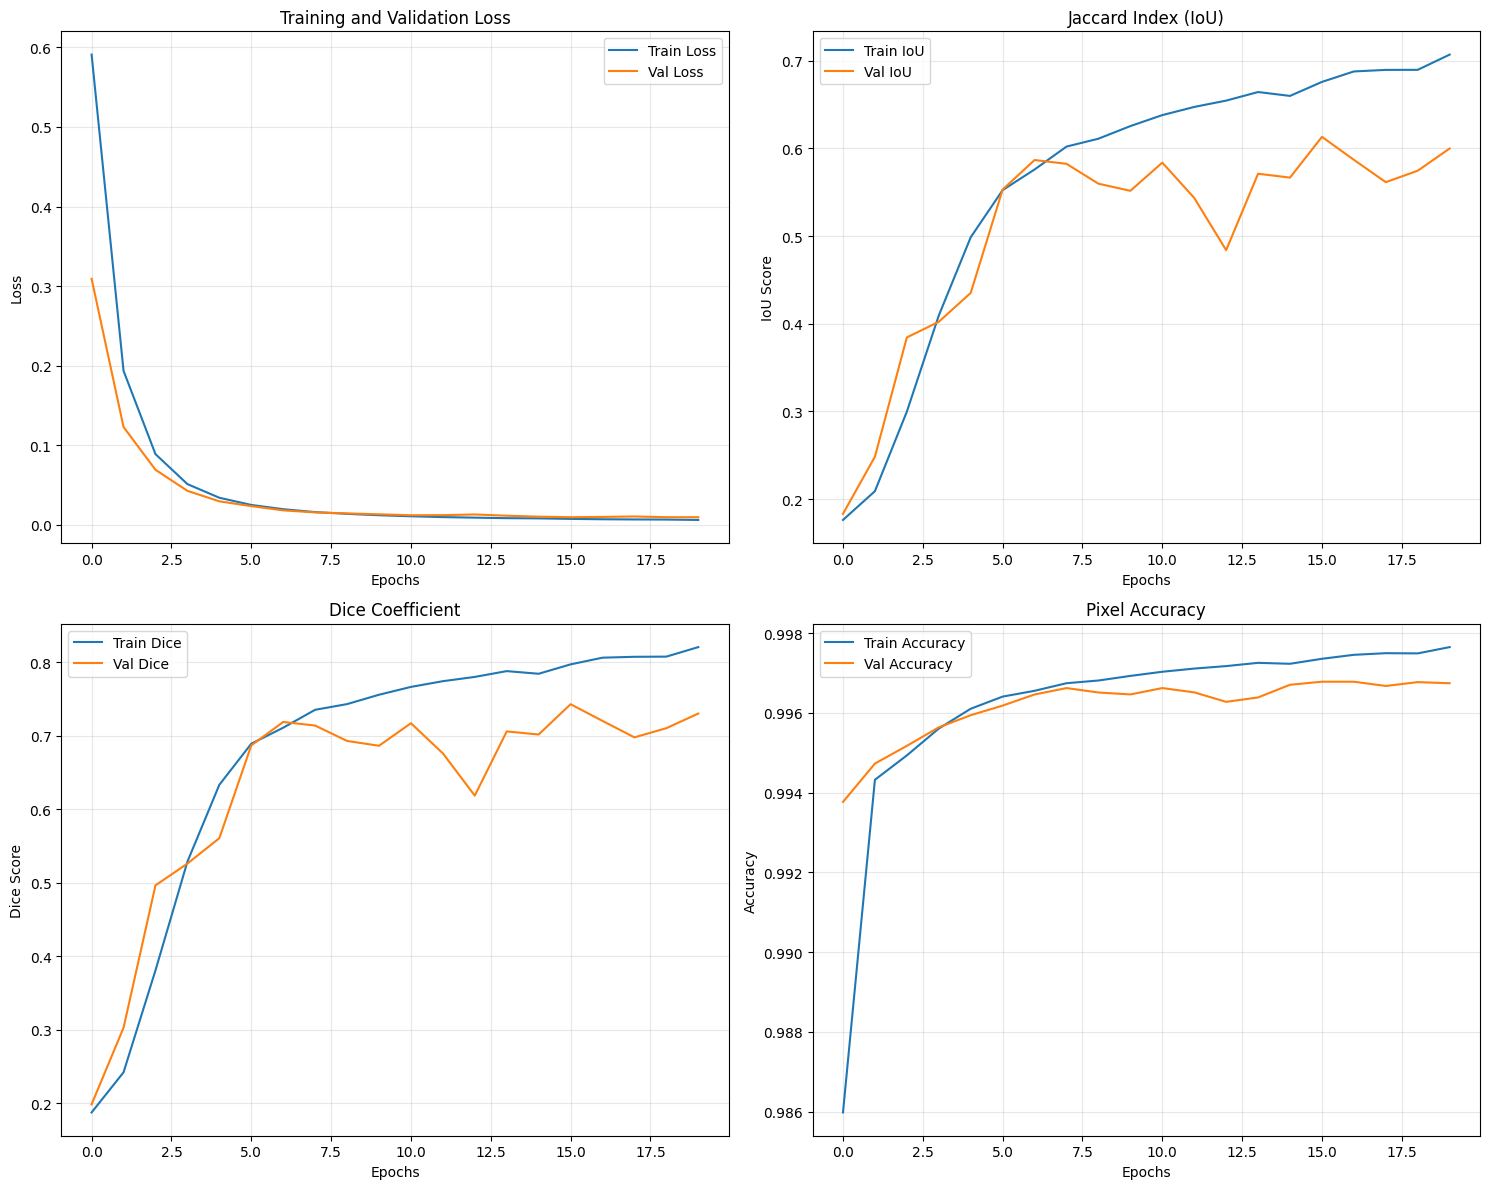

Final model saved: /kaggle/working/models/unet_seg_final.pth
Training completed successfully!


In [20]:
# Train the model
trained_model, metrics_history = main()


EXAMPLE PREDICTION
Making prediction on sample image: /kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_images/4003253/702807833/8.dcm


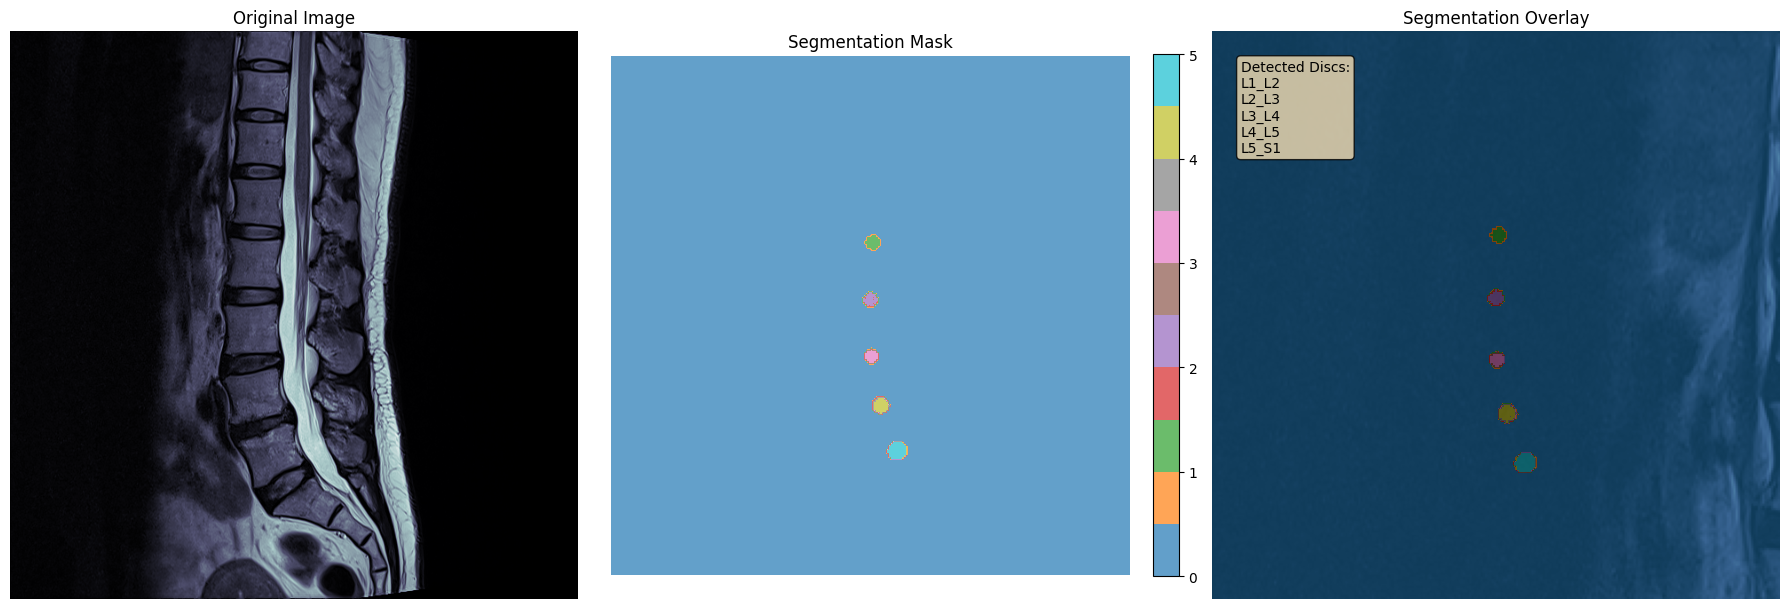

SEGMENTATION RESULTS
Detected discs: ['L1_L2', 'L2_L3', 'L3_L4', 'L4_L5', 'L5_S1']


In [21]:
print("\n" + "="*60)
print("EXAMPLE PREDICTION")
print("="*60)

# Load a sample image for prediction
if len(df) > 0:
    sample_image_path = df.iloc[0]['image_path']
    print(f"Making prediction on sample image: {sample_image_path}")
    
    # Make prediction
    results = predict_single_image_unet(trained_model, sample_image_path)
    
    # For demonstration, we'll create a dummy ground truth
    # In real usage, you would have the actual ground truth mask
    dummy_ground_truth = np.zeros_like(results['segmentation']['prediction'])
    
    # Visualize results (without ground truth metrics)
    visualize_segmentation_with_metrics(results)
else:
    print("No data available for sample prediction")

In [22]:
def load_trained_unet(model_path):
    """Load a trained U-Net model for inference"""
    model = UNet(n_channels=1, n_classes=6)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    model.eval()
    print(f"Model loaded from {model_path}")
    return model

In [23]:

# Example usage for loading pretrained model:
# model = load_trained_unet('/kaggle/working/models/unet_seg_final.pth')
# results = predict_single_image_unet(model, 'path_to_your_image.dcm')
# visualize_segmentation_with_metrics(results)

# YOLOV8

In [24]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.8 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of mkl-fft to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-random to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-umath to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 103.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.0 MB/s eta 0:00:00
   ━━━━

In [25]:
import torch
import ultralytics
from ultralytics import YOLO
import pandas as pd
import numpy as np
import os
import shutil
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from sklearn.model_selection import train_test_split
import yaml
from glob import glob
import cv2
import pydicom
import warnings
warnings.filterwarnings('ignore')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [26]:
MODEL_DIR = '/kaggle/working/models'
DATA_DIR = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/"
YOLO_DATA_DIR = '/kaggle/working/yolo_data'

In [27]:
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(YOLO_DATA_DIR, exist_ok=True)
os.makedirs(f'{YOLO_DATA_DIR}/images/train', exist_ok=True)
os.makedirs(f'{YOLO_DATA_DIR}/images/val', exist_ok=True)
os.makedirs(f'{YOLO_DATA_DIR}/labels/train', exist_ok=True)
os.makedirs(f'{YOLO_DATA_DIR}/labels/val', exist_ok=True)

In [28]:
train_df = pd.read_csv(DATA_DIR + "train.csv")
train_lcoord_df = pd.read_csv(DATA_DIR + "train_label_coordinates.csv")
train_sdesc_df = pd.read_csv(DATA_DIR + "train_series_descriptions.csv")

In [29]:
print(f"Train data shape: {train_df.shape}")
print(f"Label coordinates shape: {train_lcoord_df.shape}")
print(f"Series descriptions shape: {train_sdesc_df.shape}")

Train data shape: (1975, 26)
Label coordinates shape: (48692, 7)
Series descriptions shape: (6294, 3)


In [30]:
study_paths = glob(f"{DATA_DIR}train_images/*")
images_dict = {
    "study_id": [],
    "series_id": [],
    "instance_number": [],
    "image_path": []
}


In [31]:
# Loop through study paths
for study_path in tqdm(study_paths):
    study_id = int(study_path.split("/")[-1])
    series_paths = glob(f"{study_path}/*")
    
    # Loop through series paths
    for series_path in series_paths:
        series_id = int(series_path.split("/")[-1])
        instance_paths = glob(f"{series_path}/*")
        
        # Loop through instance paths
        for instance_path in instance_paths:
            instance_id = instance_path.split("/")[-1].split(".")[0]
            instance_number = int(instance_id.split(" ")[0])
            
            # Append the data to images_dict
            images_dict["study_id"].append(study_id)
            images_dict["series_id"].append(series_id)
            images_dict["instance_number"].append(instance_number)
            images_dict["image_path"].append(instance_path)

# Create images DataFrame
images_df = pd.DataFrame(images_dict)
print(f"Images DataFrame shape: {images_df.shape}")

100%|██████████| 1975/1975 [00:09<00:00, 203.14it/s]


Images DataFrame shape: (147218, 4)


In [32]:
# Merge to add series description
images_desc_df = images_df.merge(train_sdesc_df, on=['study_id', 'series_id'])

# Merge to add condition, level, x, y 
full_train_df = train_lcoord_df.merge(images_desc_df, on=['study_id', 'series_id', 'instance_number'])

print(f"Full training data shape: {full_train_df.shape}")

Full training data shape: (48692, 9)


In [33]:
# Filter Sagittal T2/STIR images
df = full_train_df[full_train_df['series_description'] == 'Sagittal T2/STIR'][
    ['study_id', 'series_id', 'instance_number', 'image_path', 'x', 'y', 'level']
]

# Drop duplicate levels in every series
df = df.drop_duplicates(subset=['study_id', 'series_id', 'level'])

# Replace L1/L2 format to L1_L2 to prevent path conflict
df['level'] = df['level'].apply(lambda level: level.replace("/", "_"))

print(f"Final dataset shape: {df.shape}")
print(f"Unique studies: {df['study_id'].nunique()}")
print(f"Unique series: {df['series_id'].nunique()}")

Final dataset shape: (9748, 7)
Unique studies: 1973
Unique series: 1973


In [34]:
DISC_LABELS = {
    "L1_L2": 0,
    "L2_L3": 1, 
    "L3_L4": 2,
    "L4_L5": 3,
    "L5_S1": 4
}

REVERSE_LABELS = {v: k for k, v in DISC_LABELS.items()}

print("Label mappings:")
for label, idx in DISC_LABELS.items():
    print(f"  {label}: {idx}")

Label mappings:
  L1_L2: 0
  L2_L3: 1
  L3_L4: 2
  L4_L5: 3
  L5_S1: 4


In [35]:
def dicom_to_image(dicom_path, output_path, target_size=(640, 640)):
    """Convert DICOM file to JPEG/PNG image for YOLO"""
    try:
        # Read DICOM file
        dicom = pydicom.dcmread(dicom_path)
        image = dicom.pixel_array
        
        # Normalize to 0-255
        image = (image - image.min()) / (image.max() - image.min() + 1e-6) * 255
        image = image.astype(np.uint8)
        
        # Convert to 3-channel if needed
        if len(image.shape) == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        
        # Resize to target size
        image = cv2.resize(image, target_size)
        
        # Save as JPEG
        cv2.imwrite(output_path, image)
        return True
        
    except Exception as e:
        print(f"Error converting {dicom_path}: {e}")
        return False


In [36]:
def create_yolo_annotation(image_info, df, output_label_path, image_width=640, image_height=640):
    """Create YOLO format annotation file"""
    try:
        # Get original image dimensions from DICOM
        dicom_path = image_info['image_path']
        dicom = pydicom.dcmread(dicom_path)
        orig_height, orig_width = dicom.pixel_array.shape
        
        # Get all discs for this series
        series_df = df[df['series_id'] == image_info['series_id']]
        
        annotations = []
        
        for _, row in series_df.iterrows():
            # Get original coordinates
            x_orig = row['x']
            y_orig = row['y']
            level = row['level']
            class_id = DISC_LABELS[level]
            
            # Calculate scaling factors
            width_ratio = image_width / orig_width
            height_ratio = image_height / orig_height
            
            # Convert to YOLO format (normalized coordinates)
            x_center = (x_orig * width_ratio) / image_width
            y_center = (y_orig * height_ratio) / image_height
            
            # Define bounding box size (adjust based on your needs)
            bbox_width = 70 / orig_width  # Normalized width
            bbox_height = 30 / orig_height if level == 'L5_S1' else 20 / orig_height  # Normalized height
            
            # YOLO format: class_id x_center y_center width height
            annotation = f"{class_id} {x_center:.6f} {y_center:.6f} {bbox_width:.6f} {bbox_height:.6f}"
            annotations.append(annotation)
        
        # Write annotations to file
        with open(output_label_path, 'w') as f:
            for annotation in annotations:
                f.write(annotation + '\n')
        
        return True
        
    except Exception as e:
        print(f"Error creating annotation for {image_info['image_path']}: {e}")
        return False

In [37]:
def prepare_yolo_dataset(df, train_ratio=0.8):
    """Prepare YOLO format dataset"""
    print("Preparing YOLO dataset...")
    
    # Get unique images
    unique_images = df[['study_id', 'series_id', 'instance_number', 'image_path']].drop_duplicates()
    
    # Split into train and validation
    train_images, val_images = train_test_split(unique_images, test_size=1-train_ratio, random_state=42)
    
    print(f"Training images: {len(train_images)}")
    print(f"Validation images: {len(val_images)}")
    
    # Process training images
    train_success = 0
    for idx, image_info in tqdm(train_images.iterrows(), total=len(train_images), desc="Processing training images"):
        # Convert DICOM to image
        image_filename = f"image_{image_info['study_id']}_{image_info['series_id']}_{image_info['instance_number']}.jpg"
        image_path = f'{YOLO_DATA_DIR}/images/train/{image_filename}'
        
        if dicom_to_image(image_info['image_path'], image_path):
            # Create annotation file
            label_filename = f"image_{image_info['study_id']}_{image_info['series_id']}_{image_info['instance_number']}.txt"
            label_path = f'{YOLO_DATA_DIR}/labels/train/{label_filename}'
            
            if create_yolo_annotation(image_info, df, label_path):
                train_success += 1
    
    # Process validation images
    val_success = 0
    for idx, image_info in tqdm(val_images.iterrows(), total=len(val_images), desc="Processing validation images"):
        # Convert DICOM to image
        image_filename = f"image_{image_info['study_id']}_{image_info['series_id']}_{image_info['instance_number']}.jpg"
        image_path = f'{YOLO_DATA_DIR}/images/val/{image_filename}'
        
        if dicom_to_image(image_info['image_path'], image_path):
            # Create annotation file
            label_filename = f"image_{image_info['study_id']}_{image_info['series_id']}_{image_info['instance_number']}.txt"
            label_path = f'{YOLO_DATA_DIR}/labels/val/{label_filename}'
            
            if create_yolo_annotation(image_info, df, label_path):
                val_success += 1
    
    print(f"Successfully processed: {train_success} training images, {val_success} validation images")
    return len(train_images), len(val_images)

In [38]:
def create_yolo_config():
    """Create YOLO dataset configuration file"""
    config = {
        'path': YOLO_DATA_DIR,
        'train': 'images/train',
        'val': 'images/val',
        'nc': 5,  # number of classes
        'names': ['L1_L2', 'L2_L3', 'L3_L4', 'L4_L5', 'L5_S1']
    }
    
    with open(f'{YOLO_DATA_DIR}/dataset.yaml', 'w') as f:
        yaml.dump(config, f, default_flow_style=False)
    
    print("YOLO configuration file created!")
    return config


In [39]:
print("\n" + "="*60)
print("PREPARING YOLO DATASET")
print("="*60)

train_count, val_count = prepare_yolo_dataset(df)
config = create_yolo_config()

print(f"\nDataset preparation completed!")
print(f"Training images: {train_count}")
print(f"Validation images: {val_count}")


PREPARING YOLO DATASET
Preparing YOLO dataset...
Training images: 2016
Validation images: 505


Processing validation images: 100%|██████████| 505/505 [00:09<00:00, 55.30it/s]

Successfully processed: 2016 training images, 505 validation images
YOLO configuration file created!

Dataset preparation completed!
Training images: 2016
Validation images: 505


In [40]:
def train_yolov8_model():
    """Train YOLOv8 model on our dataset"""
    print("\n" + "="*60)
    print("TRAINING YOLOv8 MODEL")
    print("="*60)
    
    # Load YOLOv8 model (you can choose different sizes: n, s, m, l, x)
    model = YOLO('yolov8n.pt')  # Using nano version for faster training
    
    # Display model information
    print("Model architecture:")
    print(model.model)
    
    # Train the model
    results = model.train(
        data=f'{YOLO_DATA_DIR}/dataset.yaml',
        epochs=50,
        imgsz=640,
        batch=16,
        patience=10,
        save=True,
        project=MODEL_DIR,
        name='yolov8_spine_detection',
        optimizer='AdamW',
        lr0=0.001,
        warmup_epochs=3,
        box=7.5,  # box loss gain
        cls=0.5,  # cls loss gain
        dfl=1.5,  # dfl loss gain
        verbose=True
    )
    
    print("Training completed!")
    return model, results


In [41]:
def evaluate_model(model):
    """Evaluate the trained model"""
    print("\n" + "="*60)
    print("MODEL EVALUATION")
    print("="*60)
    
    # Evaluate on validation set
    metrics = model.val(
        data=f'{YOLO_DATA_DIR}/dataset.yaml',
        split='val',
        save_json=True,
        save_hybrid=True
    )
    
    # Print metrics
    print("\nValidation Metrics:")
    print(f"mAP50: {metrics.box.map50:.4f}")
    print(f"mAP50-95: {metrics.box.map:.4f}")
    print(f"Precision: {metrics.box.precision:.4f}")
    print(f"Recall: {metrics.box.recall:.4f}")
    
    return metrics


In [42]:
def predict_and_visualize(model, image_path, confidence_threshold=0.5):
    """Run prediction on a single image and visualize results"""
    print(f"\nRunning prediction on: {image_path}")
    
    # Convert DICOM to image for prediction
    temp_image_path = '/kaggle/working/temp_prediction.jpg'
    if dicom_to_image(image_path, temp_image_path):
        # Run prediction
        results = model.predict(
            source=temp_image_path,
            conf=confidence_threshold,
            save=False,
            save_txt=False
        )
        
        # Visualize results
        if len(results) > 0 and len(results[0].boxes) > 0:
            plot_yolo_prediction(temp_image_path, results[0])
        else:
            print("No detections found!")
        
        # Clean up temp file
        if os.path.exists(temp_image_path):
            os.remove(temp_image_path)
        
        return results
    else:
        print("Failed to convert DICOM for prediction")
        return None

def plot_yolo_prediction(image_path, result):
    """Plot YOLO prediction results"""
    # Read image
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    
    # Original image
    axes[0].imshow(image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    # Image with bounding boxes
    axes[1].imshow(image)
    
    # Extract bounding boxes
    boxes = result.boxes
    if len(boxes) > 0:
        for box in boxes:
            # Get box coordinates (x1, y1, x2, y2)
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            confidence = box.conf[0].cpu().numpy()
            class_id = int(box.cls[0].cpu().numpy())
            class_name = REVERSE_LABELS[class_id]
            
            # Create rectangle
            width = x2 - x1
            height = y2 - y1
            rect = patches.Rectangle(
                (x1, y1), width, height,
                linewidth=2, edgecolor='red', facecolor='none'
            )
            axes[1].add_patch(rect)
            
            # Add label
            label = f"{class_name} {confidence:.2f}"
            axes[1].text(
                x1, y1 - 10, label,
                color='red', fontsize=12, fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7)
            )
    
    axes[1].set_title('YOLO Detection Results')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
    
    # Print detection details
    print("\nDetection Details:")
    print("=" * 40)
    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        confidence = box.conf[0].cpu().numpy()
        class_id = int(box.cls[0].cpu().numpy())
        class_name = REVERSE_LABELS[class_id]
        
        print(f"Detection {i+1}:")
        print(f"  Class: {class_name}")
        print(f"  Confidence: {confidence:.4f}")
        print(f"  BBox: [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")
        print(f"  Size: {x2-x1:.1f} x {y2-y1:.1f}")
        print()


In [43]:
def calculate_detection_metrics(model, val_images_path, confidence_threshold=0.5):
    """Calculate comprehensive detection metrics"""
    print("\n" + "="*60)
    print("CALCULATING DETECTION METRICS")
    print("="*60)
    
    # Run batch prediction
    results = model.predict(
        source=val_images_path,
        conf=confidence_threshold,
        save=False,
        save_txt=False,
        save_conf=True
    )
    
    # Calculate metrics manually
    total_detections = 0
    class_detections = {class_id: 0 for class_id in range(5)}
    confidence_scores = []
    
    for result in results:
        boxes = result.boxes
        total_detections += len(boxes)
        
        for box in boxes:
            class_id = int(box.cls[0].cpu().numpy())
            confidence = box.conf[0].cpu().numpy()
            class_detections[class_id] += 1
            confidence_scores.append(confidence)
    
    print(f"Total detections: {total_detections}")
    print("\nDetections per class:")
    for class_id, count in class_detections.items():
        class_name = REVERSE_LABELS[class_id]
        print(f"  {class_name}: {count}")
    
    if confidence_scores:
        print(f"\nAverage confidence: {np.mean(confidence_scores):.4f}")
        print(f"Confidence std: {np.std(confidence_scores):.4f}")
        print(f"Min confidence: {np.min(confidence_scores):.4f}")
        print(f"Max confidence: {np.max(confidence_scores):.4f}")
    
    return {
        'total_detections': total_detections,
        'class_detections': class_detections,
        'confidence_stats': {
            'mean': np.mean(confidence_scores) if confidence_scores else 0,
            'std': np.std(confidence_scores) if confidence_scores else 0,
            'min': np.min(confidence_scores) if confidence_scores else 0,
            'max': np.max(confidence_scores) if confidence_scores else 0
        }
    }


In [44]:
def main():
    """Main execution function"""
    # Train the model
    model, results = train_yolov8_model()
    
    # Evaluate the model
    metrics = evaluate_model(model)
    
    # Save the best model
    best_model_path = f"{MODEL_DIR}/yolov8_spine_detection/weights/best.pt"
    if os.path.exists(best_model_path):
        print(f"\nBest model saved at: {best_model_path}")
    
    # Load best model for inference
    best_model = YOLO(best_model_path)
    
    # Run sample prediction
    if len(df) > 0:
        sample_image_path = df.iloc[0]['image_path']
        print(f"\nRunning sample prediction on: {sample_image_path}")
        prediction_results = predict_and_visualize(best_model, sample_image_path)
    
    # Calculate batch metrics
    val_images_path = f'{YOLO_DATA_DIR}/images/val'
    batch_metrics = calculate_detection_metrics(best_model, val_images_path)
    
    return best_model, metrics, batch_metrics


In [45]:
try:
    model, metrics, batch_metrics = main()
    print("\n" + "="*60)
    print("YOLOv8 TRAINING COMPLETED SUCCESSFULLY!")
    print("="*60)
except Exception as e:
    print(f"Error in main execution: {e}")
    import traceback
    traceback.print_exc()


TRAINING YOLOv8 MODEL
Model architecture:
DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
   

Traceback (most recent call last):
  File "/tmp/ipykernel_19/882339265.py", line 2, in <cell line: 0>
    model, metrics, batch_metrics = main()
                                    ^^^^^^
  File "/tmp/ipykernel_19/4023918182.py", line 7, in main
    metrics = evaluate_model(model)
              ^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_19/1058966016.py", line 19, in evaluate_model
    print(f"Precision: {metrics.box.precision:.4f}")
                        ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/ultralytics/utils/__init__.py", line 274, in __getattr__
    raise AttributeError(f"'{name}' object has no attribute '{attr}'. See valid attributes below.\n{self.__doc__}")
AttributeError: 'Metric' object has no attribute 'precision'. See valid attributes below.

    Class for computing evaluation metrics for Ultralytics YOLO models.

    Attributes:
        p (list): Precision for each class. Shape: (nc,).
        r (list): Recall for each class. Shape: (nc,).


In [46]:
def load_trained_yolo(model_path):
    """Load a trained YOLO model for inference"""
    model = YOLO(model_path)
    print(f"Model loaded from {model_path}")
    return model